# KHAI PHÁ DỮ LIỆU — LAB 1 · Phần 2 · Bài 2 (Trang 37–38): Luật kết hợp trên dữ liệu Online Retail

            | | |
            |---|---|
            | **Sinh viên** | Phan Quốc Thắng |
            | **MSSV** | 6451071073 |
            | **Lớp** | CNTT-K64 |
            | **GVHD** | ThS. Nguyễn Thiện Dương |

            **Dữ liệu:** `data/Online Retail.xlsx` — lịch sử bán hàng của một cửa hàng bán lẻ trực tuyến tại châu Âu
(UCI Machine Learning Repository). Thư viện: `mlxtend` (Apriori, FP-Growth), `openpyxl` để đọc file Excel.

## Khai báo thông tin sinh viên & thư viện

In [1]:
HO_TEN = "Phan Quốc Thắng"
MSSV = "6451071073"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
SEED = int(MSSV[-4:])          # seed lấy từ MSSV để kết quả tái lập được
rng = np.random.default_rng(SEED)
DATA = "../data/"

from scipy.sparse import coo_matrix
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


## Câu 1: Đọc dữ liệu vào chương trình

In [2]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df = pd.read_excel(DATA + "Online Retail.xlsx")
print("Kích thước dữ liệu:", df.shape)
display(df.head())
df.info()

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Kích thước dữ liệu: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


**Nhận xét:**

- Dữ liệu có **541 909 dòng × 8 cột**. `Description` thiếu 1 454 giá trị, `CustomerID` thiếu 135 080 giá trị (khoảng 25%).
- `InvoiceNo` có kiểu object vì lẫn giữa số (536365) và chuỗi (`C536379` của hoá đơn tín dụng), nên cần đưa về cùng kiểu chuỗi.

## Câu 2: Tiền xử lý: cắt ký tự thừa ở Description, xoá dòng không có InvoiceNo, chuyển InvoiceNo về kiểu chuỗi

In [3]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df["Description"] = df["Description"].str.strip()
truoc = len(df)
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
print(f"Số dòng trước: {truoc} | sau khi xoá dòng thiếu InvoiceNo: {len(df)}")
print("Kiểu dữ liệu InvoiceNo:", df["InvoiceNo"].dtype)
display(df.head(10))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Số dòng trước: 541909 | sau khi xoá dòng thiếu InvoiceNo: 541909
Kiểu dữ liệu InvoiceNo: str


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


**Nhận xét:**

- Không có dòng nào thiếu `InvoiceNo` (số dòng giữ nguyên 541 909). `InvoiceNo` đã được chuyển sang kiểu chuỗi.
- `str.strip()` loại bỏ khoảng trắng thừa ở đầu và cuối tên mặt hàng, tránh trường hợp cùng một sản phẩm bị tính thành hai cột khác nhau khi pivot.

## Câu 3: Xoá các hoá đơn tín dụng (InvoiceNo chứa ký tự 'C')

In [4]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
tin_dung = df[df["InvoiceNo"].str.contains("C")]
print("Ví dụ hoá đơn tín dụng:"); display(tin_dung.head())
print("Số dòng thuộc hoá đơn tín dụng:", len(tin_dung))
df = df[~df["InvoiceNo"].str.contains("C")]
print("Số dòng còn lại:", len(df))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Ví dụ hoá đơn tín dụng:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Số dòng thuộc hoá đơn tín dụng: 9288
Số dòng còn lại: 532621


**Nhận xét:**

- Có **9 288 dòng thuộc hoá đơn tín dụng** (mã bắt đầu bằng `C`, số lượng âm, là hàng trả lại hoặc giảm giá). Sau khi xoá còn 532 621 dòng.
- Hoá đơn trả hàng không phải hành vi "mua cùng nhau", nên giữ lại sẽ làm sai độ hỗ trợ của các tập mục.

## Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Số quốc gia: 38


Country,United Kingdom,Germany,France,EIRE,Spain,Netherlands,Belgium,Switzerland,Portugal,Australia,Norway,Italy,Channel Islands,Finland,Cyprus,Sweden,Unspecified,Austria,Denmark,Poland,Japan,Israel,Hong Kong,Singapore,Iceland,USA,Canada,Greece,Malta,United Arab Emirates,European Community,RSA,Lebanon,Lithuania,Brazil,Czech Republic,Bahrain,Saudi Arabia
So_dong,487622,9042,8408,7894,2485,2363,2031,1967,1501,1185,1072,758,748,685,614,451,446,398,380,330,321,295,284,222,182,179,151,145,112,68,60,58,45,35,32,25,18,9


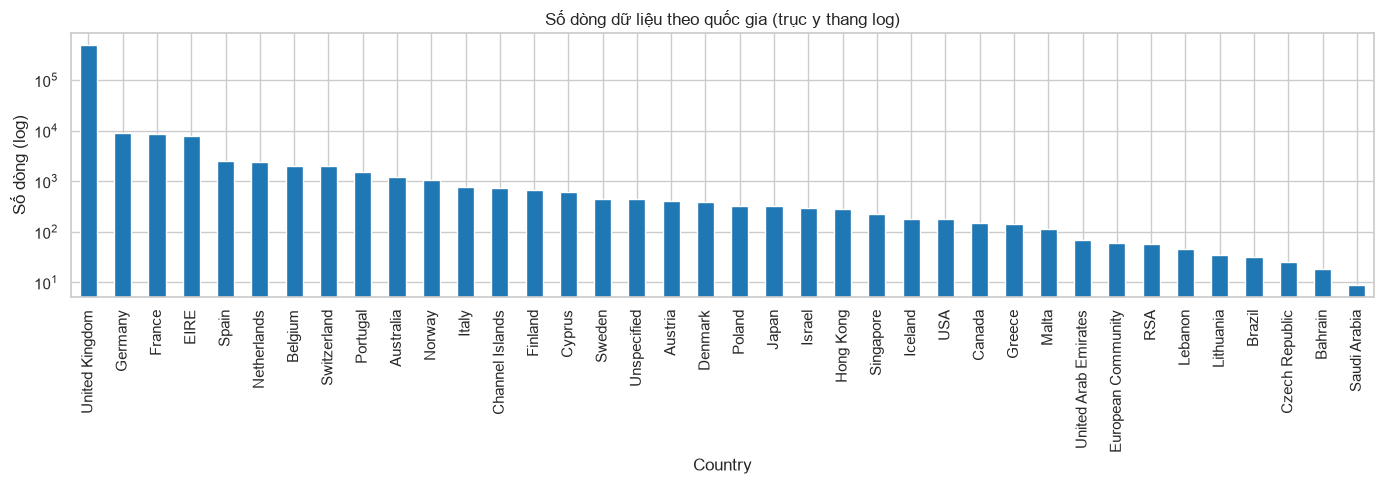

In [5]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
country = df["Country"].value_counts()
print("Số quốc gia:", country.size)
display(country.to_frame("So_dong").T)
fig, ax = plt.subplots(figsize=(14, 5))
country.plot(kind="bar", ax=ax, color="tab:blue", logy=True)
ax.set_title("Số dòng dữ liệu theo quốc gia (trục y thang log)"); ax.set_xlabel("Country"); ax.set_ylabel("Số dòng (log)")
plt.tight_layout(); plt.show()

**Nhận xét:**

- Dữ liệu đến từ **38 quốc gia** nhưng tập trung rất lệch: United Kingdom có 487 622 dòng (91.6%), tiếp theo Germany 9 042, France 8 408, EIRE 7 894. Phần lớn các nước còn lại có dưới 1 000 dòng.
- Vì vậy biểu đồ dùng trục log. Các luật kết hợp nên được tìm riêng theo từng thị trường, vì gộp chung thì kết quả sẽ gần như chỉ phản ánh hành vi khách Anh.

## Câu 5: Lấy dữ liệu nước Anh, gom nhóm Quantity theo InvoiceNo và Description

In [6]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
uk = df[df["Country"] == "United Kingdom"]
s = uk.groupby(["InvoiceNo", "Description"])["Quantity"].sum()
print("Số dòng UK:", len(uk), "| Số cặp (hoá đơn, mặt hàng):", len(s))
display(s.head(10).to_frame())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Số dòng UK: 487622 | Số cặp (hoá đơn, mặt hàng): 475560


Quantity
InvoiceNo Description                                  
536365    CREAM CUPID HEARTS COAT HANGER              8
          GLASS STAR FROSTED T-LIGHT HOLDER           6
          KNITTED UNION FLAG HOT WATER BOTTLE         6
          RED WOOLLY HOTTIE WHITE HEART.              6
          SET 7 BABUSHKA NESTING BOXES                2
          WHITE HANGING HEART T-LIGHT HOLDER          6
          WHITE METAL LANTERN                         6
536366    HAND WARMER RED POLKA DOT                   6
          HAND WARMER UNION JACK                      6
536367    ASSORTED COLOUR BIRD ORNAMENT              32

**Nhận xét:**

- 487 622 dòng của UK được gom thành **475 560 cặp (hoá đơn, mặt hàng)**. Số lượng của cùng một mặt hàng xuất hiện nhiều lần trong một hoá đơn được cộng dồn.
- Ví dụ hoá đơn 536365 gồm 7 mặt hàng như WHITE HANGING HEART T-LIGHT HOLDER (6), CREAM CUPID HEARTS COAT HANGER (8), …

## Câu 6: Chuyển dữ liệu về dạng hot encoding — mỗi dòng là một hoá đơn

In [7]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
# unstack() dạng dense cần vài trăm MB RAM -> dựng ma trận thưa (sparse) tương đương, kết quả giống hệt
inv_code, inv_idx = pd.factorize(s.index.get_level_values(0))
itm_code, itm_idx = pd.factorize(s.index.get_level_values(1), sort=True)
M = coo_matrix((s.values.astype(np.int32), (inv_code, itm_code)), shape=(len(inv_idx), len(itm_idx))).tocsr()
basket = pd.DataFrame.sparse.from_spmatrix(M, index=inv_idx, columns=itm_idx)
basket.index.name = "InvoiceNo"
print("Kích thước basket (số hoá đơn, số mặt hàng):", basket.shape)
display(basket.iloc[:5, :8])

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Kích thước basket (số hoá đơn, số mặt hàng): (18667, 4175)


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0


**Nhận xét:**

- Ma trận hot encoding có kích thước **18 667 hoá đơn × 4 175 mặt hàng**, nhưng chỉ khoảng 475 560 / (18 667 × 4 175) ≈ **0.61%** số ô khác 0, tức ma trận rất thưa.
- Nếu dùng `unstack()` dạng dense như hướng dẫn thì cần khoảng 600 MB RAM. Bài làm dựng ma trận thưa (sparse) cho kết quả y hệt nhưng tiết kiệm bộ nhớ hơn nhiều.

## Câu 7: Chuyển từ hot encoding sang one-hot encoding (Quantity > 0 -> 1, ngược lại 0)

In [8]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
def encode_units(x):
    return 1 if x > 0 else 0          # hàm biến đổi như hướng dẫn (áp dụng vectơ hoá bên dưới)

basket_sets = pd.DataFrame(M.toarray() > 0, index=basket.index, columns=basket.columns)
print("Kiểm tra hàm encode_units:", [encode_units(v) for v in [-2, 0, 3]])
print("Kích thước basket_sets:", basket_sets.shape, "| kiểu:", basket_sets.dtypes.iloc[0])
display(basket_sets.iloc[:5, :8].astype(int))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Kiểm tra hàm encode_units: [0, 0, 1]
Kích thước basket_sets: (18667, 4175) | kiểu: bool


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0


**Nhận xét:**

- Mỗi ô được chuyển thành True/False theo quy tắc của hàm `encode_units` (> 0 → 1, ngược lại 0). Hàm được kiểm tra với các giá trị [−2, 0, 3] → [0, 0, 1].
- Kiểu `bool` là kiểu được `mlxtend` khuyến nghị: tốn 1 byte/ô (≈ 78 MB cho cả ma trận) và chạy nhanh hơn kiểu số.

## Câu 8: Xoá cột 'POSTAGE' (tiền cước phí)

In [9]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
print("Có cột POSTAGE:", "POSTAGE" in basket_sets.columns)
basket_sets = basket_sets.drop(columns=["POSTAGE"], errors="ignore")
print("Kích thước sau khi xoá:", basket_sets.shape, "| còn POSTAGE:", "POSTAGE" in basket_sets.columns)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Có cột POSTAGE: True
Kích thước sau khi xoá: (18667, 4174) | còn POSTAGE: False


**Nhận xét:**

- Cột `POSTAGE` có tồn tại và đã được xoá, còn lại 4 174 mặt hàng. `POSTAGE` là phí vận chuyển xuất hiện trong rất nhiều hoá đơn, nếu giữ lại sẽ sinh ra các luật vô nghĩa dạng "X ⇒ POSTAGE".

## Câu 9: Tìm tập phổ biến bằng thuật toán Apriori với min_sup = 3%

In [10]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
t0 = time.perf_counter()
frequent_ap = apriori(basket_sets, min_support=0.03, use_colnames=True)
t_ap = time.perf_counter() - t0
frequent_ap["length"] = frequent_ap["itemsets"].apply(len)
print(f"Số tập phổ biến: {len(frequent_ap)} | thời gian Apriori: {t_ap:.2f} s")
print("Số tập theo độ dài:", frequent_ap["length"].value_counts().sort_index().to_dict())
display(frequent_ap.sort_values("support", ascending=False).head(10))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Số tập phổ biến: 131 | thời gian Apriori: 0.31 s
Số tập theo độ dài: {1: 123, 2: 8}


,support,itemsets,length
118,0.116034,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
52,0.103820,frozenset({JUMBO BAG RED RETROSPOT}),1
95,0.090266,frozenset({REGENCY CAKESTAND 3 TIER}),1
84,0.085391,frozenset({PARTY BUNTING}),1
69,0.074570,frozenset({LUNCH BAG RED RETROSPOT}),1
7,0.073445,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
103,0.066481,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
75,0.065302,frozenset({NATURAL SLATE HEART CHALKBOARD}),1
63,0.065142,frozenset({LUNCH BAG BLACK SKULL.}),1
35,0.062356,frozenset({HEART OF WICKER SMALL}),1


**Nhận xét:**

- Với min_sup = 3% (≥ 560 hoá đơn), Apriori tìm được **131 tập phổ biến**, gồm 123 tập 1 phần tử và 8 tập 2 phần tử, không có tập 3 phần tử. Lý do là có tới 4 174 mặt hàng nên rất ít cặp mặt hàng đạt ngưỡng 3%.
- Mặt hàng bán chạy nhất là WHITE HANGING HEART T-LIGHT HOLDER (11.6% hoá đơn), tiếp theo là JUMBO BAG RED RETROSPOT (10.4%) và REGENCY CAKESTAND 3 TIER (9.0%).

## Câu 10: Tạo luật kết hợp với min_conf = 50% và in ra các luật

In [11]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
rules_ap = association_rules(frequent_ap, metric="confidence", min_threshold=0.5)
rules_ap["antecedents"] = rules_ap["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_ap["consequents"] = rules_ap["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules_ap = rules_ap.sort_values("confidence", ascending=False).reset_index(drop=True)
print("Số luật tìm được:", len(rules_ap))
display(rules_ap[["antecedents", "consequents", "support", "confidence", "lift"]].round(4))
for _, r in rules_ap.iterrows():
    print(f"{{{r['antecedents']}}} => {{{r['consequents']}}}  (sup = {r['support']:.4f}, conf = {r['confidence']:.4f}, lift = {r['lift']:.2f})")

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Số luật tìm được: 10


,antecedents,consequents,support,confidence,lift
0,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0309,0.8208,16.4039
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0376,0.7505,14.6398
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0376,0.7325,14.6398
3,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.0421,0.6773,6.5239
4,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0302,0.6427,12.9002
5,JUMBO BAG BAROQUE BLACK WHITE,JUMBO BAG RED RETROSPOT,0.0305,0.6264,6.0333
6,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.0309,0.6178,16.4039
7,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.0374,0.6177,5.9497
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0302,0.6054,12.9002
9,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.0352,0.5799,5.5854


{PINK REGENCY TEACUP AND SAUCER} => {GREEN REGENCY TEACUP AND SAUCER}  (sup = 0.0309, conf = 0.8208, lift = 16.40)
{GREEN REGENCY TEACUP AND SAUCER} => {ROSES REGENCY TEACUP AND SAUCER}  (sup = 0.0376, conf = 0.7505, lift = 14.64)
{ROSES REGENCY TEACUP AND SAUCER} => {GREEN REGENCY TEACUP AND SAUCER}  (sup = 0.0376, conf = 0.7325, lift = 14.64)
{JUMBO BAG PINK POLKADOT} => {JUMBO BAG RED RETROSPOT}  (sup = 0.0421, conf = 0.6773, lift = 6.52)
{ALARM CLOCK BAKELIKE GREEN} => {ALARM CLOCK BAKELIKE RED}  (sup = 0.0302, conf = 0.6427, lift = 12.90)
{JUMBO  BAG BAROQUE BLACK WHITE} => {JUMBO BAG RED RETROSPOT}  (sup = 0.0305, conf = 0.6264, lift = 6.03)
{GREEN REGENCY TEACUP AND SAUCER} => {PINK REGENCY TEACUP AND SAUCER}  (sup = 0.0309, conf = 0.6178, lift = 16.40)
{JUMBO STORAGE BAG SUKI} => {JUMBO BAG RED RETROSPOT}  (sup = 0.0374, conf = 0.6177, lift = 5.95)
{ALARM CLOCK BAKELIKE RED} => {ALARM CLOCK BAKELIKE GREEN}  (sup = 0.0302, conf = 0.6054, lift = 12.90)
{JUMBO SHOPPER VINTAGE RED 

**Nhận xét:**

- Có **10 luật** thoả min_conf = 50%. Mạnh nhất là {PINK REGENCY TEACUP AND SAUCER} ⇒ {GREEN REGENCY TEACUP AND SAUCER}: 82.1% khách mua tách màu hồng cũng mua tách màu xanh, lift = 16.4.
- Các luật gom thành 3 nhóm sản phẩm: bộ tách trà *Regency* (3 màu), đồng hồ *Alarm clock bakelike* (xanh ⇔ đỏ, lift 12.9) và túi *Jumbo bag* (các mẫu khác nhau ⇒ JUMBO BAG RED RETROSPOT, lift 5.6 – 6.5).
- Mọi luật đều có lift > 1, nghĩa là hai vế tương quan dương thật sự chứ không chỉ do vế phải phổ biến. Gợi ý kinh doanh: bán theo combo nhiều màu của cùng một dòng sản phẩm.

## Câu 11: Biểu diễn độ tin cậy, độ hỗ trợ của tập luật lên đồ thị phân tán

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


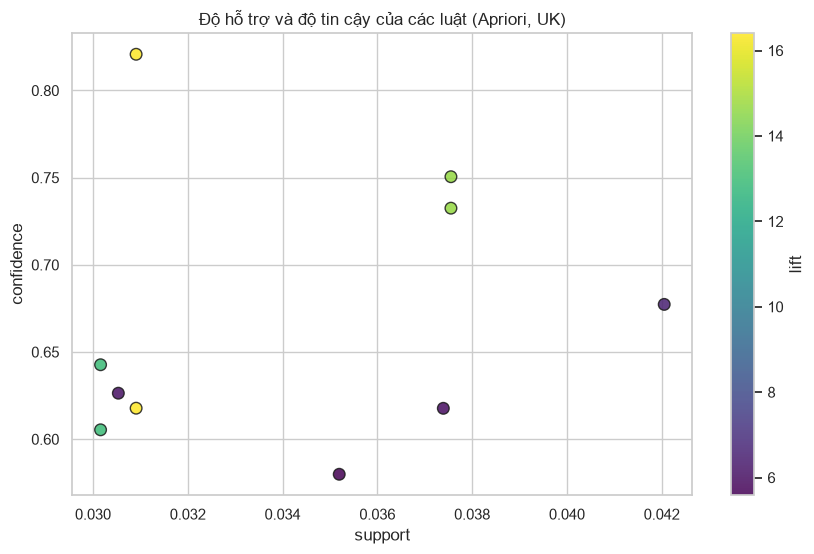

In [12]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
support, confidence = rules_ap["support"].values, rules_ap["confidence"].values
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(support, confidence, c=rules_ap["lift"], cmap="viridis", s=70, alpha=0.85, edgecolors="k")
plt.colorbar(sc, label="lift")
ax.set_title("Độ hỗ trợ và độ tin cậy của các luật (Apriori, UK)"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
plt.show()

**Nhận xét:**

- Tất cả các luật nằm trong vùng support 0.030 – 0.042 và confidence 0.58 – 0.82. Support thấp vì có quá nhiều mặt hàng, nhưng confidence khá cao.
- Không có xu hướng "support cao thì confidence cao". Các luật về tách trà Regency (màu vàng, lift khoảng 15 – 16) có confidence cao nhất dù support chỉ khoảng 0.03 – 0.04. Các luật Jumbo bag có support cao hơn (đến 0.042) nhưng lift thấp hơn (khoảng 6).

## Câu 12: Tìm tập phổ biến và luật kết hợp bằng FP-Growth (min_sup = 3%, min_conf = 50%) và so sánh với Apriori

In [13]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
t0 = time.perf_counter()
frequent_fp = fpgrowth(basket_sets, min_support=0.03, use_colnames=True)
t_fp = time.perf_counter() - t0
rules_fp = association_rules(frequent_fp, metric="confidence", min_threshold=0.5)
rules_fp["antecedents"] = rules_fp["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_fp["consequents"] = rules_fp["consequents"].apply(lambda x: ", ".join(sorted(x)))
print(f"FP-Growth: {len(frequent_fp)} tập phổ biến, {len(rules_fp)} luật, thời gian {t_fp:.2f} s")
display(rules_fp.sort_values("confidence", ascending=False)[["antecedents", "consequents", "support", "confidence", "lift"]].round(4).reset_index(drop=True))

same_items = set(frequent_ap["itemsets"]) == set(frequent_fp["itemsets"])
same_rules = set(zip(rules_ap.antecedents, rules_ap.consequents)) == set(zip(rules_fp.antecedents, rules_fp.consequents))
display(pd.DataFrame({"Apriori": [len(frequent_ap), len(rules_ap), round(t_ap, 3)],
                      "FP-Growth": [len(frequent_fp), len(rules_fp), round(t_fp, 3)]},
                     index=["Số tập phổ biến", "Số luật", "Thời gian tìm tập phổ biến (s)"]))
print("Tập phổ biến giống nhau:", same_items, "| Tập luật giống nhau:", same_rules)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


FP-Growth: 131 tập phổ biến, 10 luật, thời gian 1.06 s


,antecedents,consequents,support,confidence,lift
0,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0309,0.8208,16.4039
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0376,0.7505,14.6398
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0376,0.7325,14.6398
3,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.0421,0.6773,6.5239
4,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0302,0.6427,12.9002
5,JUMBO BAG BAROQUE BLACK WHITE,JUMBO BAG RED RETROSPOT,0.0305,0.6264,6.0333
6,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.0309,0.6178,16.4039
7,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.0374,0.6177,5.9497
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0302,0.6054,12.9002
9,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.0352,0.5799,5.5854


,Apriori,FP-Growth
Số tập phổ biến,131.000,131.000
Số luật,10.000,10.000
Thời gian tìm tập phổ biến (s),0.306,1.064


Tập phổ biến giống nhau: True | Tập luật giống nhau: True


**Nhận xét:**

- FP-Growth tìm được **đúng 131 tập phổ biến và 10 luật giống hệt Apriori** (kiểm tra bằng so sánh tập hợp: `True`, `True`).
- Thời gian: Apriori khoảng **0.31 s**, FP-Growth khoảng **1.06 s**. Ở ngưỡng 3%, Apriori chỉ phải đi tới tập 2 phần tử (khoảng C(123, 2) = 7 503 ứng viên). Bản cài đặt của `mlxtend` đếm support bằng phép toán NumPy trên ma trận bool nên rất nhanh.
- FP-Growth luôn phải dựng cây FP từ 18 667 hoá đơn bằng các vòng lặp Python, nên tốn chi phí cố định. Ưu thế của FP-Growth chỉ thể hiện khi có nhiều tập phổ biến dài, tức min_sup thấp (xem Bài 6).

## Kết luận

- Quy trình gồm làm sạch → lọc theo thị trường → mã hoá one-hot → Apriori/FP-Growth → luật kết hợp. Kết quả cho thấy khách UK thường mua **nhiều màu/mẫu của cùng một dòng sản phẩm** (tách trà Regency, đồng hồ Bakelike, túi Jumbo).
- Apriori và FP-Growth cho kết quả giống hệt nhau. Thời gian chạy chỉ khác nhau do cách cài đặt và mật độ dữ liệu.